# Retail Sales Analysis: Data Preprocessing and Basic EDA

**Program:** Data Science, Part 1 (Month 1): Python Basics and Data Manipulation
**Dataset:** `Retail_Sales_Dataset.csv` (10,000 transactions, Jan 2023 to Dec 2024)
**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn

### What this notebook does
1. Loads the data and gets a first feel for it using core Python (variables, loops, dictionaries, sets, functions).
2. Preprocesses the data: missing values, duplicates, data types, consistency checks, outliers and new features.
3. Runs a basic EDA: distributions, segment comparisons, trends over time and relationships between features.
4. Pulls the findings together, including what the data can and cannot tell us.

One thing to say upfront: this dataset arrives very clean. There are no missing values and no duplicates, so the preprocessing section is more about proving that with checks than about repairing damage. I kept the checks in anyway, because verifying is part of the job.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.dpi"] = 110

os.makedirs("images", exist_ok=True)

def save_fig(name):
    """Tidy the layout, save the current figure into images/ and show it."""
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def fmt_inr(x):
    """Format a rupee amount in lakhs / crores so large totals stay readable."""
    if x >= 1e7:
        return f"₹{x / 1e7:,.2f} Cr"
    elif x >= 1e5:
        return f"₹{x / 1e5:,.2f} L"
    else:
        return f"₹{x:,.0f}"

The file has no currency column. The cities are all Indian and the prices fit rupee ranges, so I am assuming the amounts are in INR (₹).

## 2. Loading the data and first look

In [2]:
df = pd.read_csv("data/Retail_Sales_Dataset.csv")

n_rows, n_cols = df.shape          # tuple unpacking
print(f"Rows: {n_rows:,} | Columns: {n_cols}")
df.head()

Rows: 10,000 | Columns: 21


,TransactionID,Date,Month,Quarter,Year,City,Region,Category,ProductName,Channel,PaymentMethod,Gender,Quantity,UnitPrice,Discount,Revenue,Cost,Profit,ProfitMargin,CustomerRating,Returned
0,TXN07641,2023-01-01,January,Q1,2023,Jaipur,North,Electronics,Monitor,Offline,Debit Card,Female,1,"9,111.29",0.10,"9,840.19","5,752.71","4,087.48",41.54,4.70,0
1,TXN07172,2023-01-01,January,Q1,2023,Delhi,North,Electronics,Monitor,Offline,Net Banking,Female,1,"11,670.69",0.05,"13,304.59","8,852.98","4,451.61",33.46,3.00,0
2,TXN08048,2023-01-01,January,Q1,2023,Chennai,South,Sports,Dumbbells,Offline,UPI,Male,1,920.25,0.15,938.65,629.71,308.94,32.91,3.40,0
3,TXN07941,2023-01-01,January,Q1,2023,Jaipur,North,Clothing,T-Shirt,Offline,UPI,Male,1,916.72,0.10,990.06,579.06,411.00,41.51,4.10,0
4,TXN03836,2023-01-01,January,Q1,2023,Hyderabad,South,Sports,Swimming Goggles,Mobile App,Net Banking,Female,5,"1,450.49",0.00,"8,702.94","5,777.10","2,925.84",33.62,3.00,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TransactionID   10000 non-null  str    
 1   Date            10000 non-null  str    
 2   Month           10000 non-null  str    
 3   Quarter         10000 non-null  str    
 4   Year            10000 non-null  int64  
 5   City            10000 non-null  str    
 6   Region          10000 non-null  str    
 7   Category        10000 non-null  str    
 8   ProductName     10000 non-null  str    
 9   Channel         10000 non-null  str    
 10  PaymentMethod   10000 non-null  str    
 11  Gender          10000 non-null  str    
 12  Quantity        10000 non-null  int64  
 13  UnitPrice       10000 non-null  float64
 14  Discount        10000 non-null  float64
 15  Revenue         10000 non-null  float64
 16  Cost            10000 non-null  float64
 17  Profit          10000 non-null  float64
 18

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,"10,000.00","2,023.51",0.50,"2,023.00","2,023.00","2,024.00","2,024.00","2,024.00"
Quantity,"10,000.00",2.09,1.30,1.00,1.00,2.00,3.00,6.00
UnitPrice,"10,000.00","5,002.32","5,424.47",60.00,624.58,"1,199.58","9,483.47","22,367.26"
Discount,"10,000.00",0.08,0.08,0.00,0.00,0.05,0.15,0.25
Revenue,"10,000.00","11,051.18","16,495.90",46.46,764.77,"3,396.48","14,684.15","145,688.00"
Cost,"10,000.00","7,348.86","11,056.81",27.50,509.14,"2,259.32","9,780.70","104,644.18"
Profit,"10,000.00","3,702.32","5,685.63",11.42,253.11,"1,127.10","4,870.56","63,468.66"
ProfitMargin,"10,000.00",33.55,6.64,22.00,27.75,33.64,39.31,45.00
CustomerRating,"10,000.00",3.76,0.84,1.00,3.20,3.80,4.40,5.00
Returned,"10,000.00",0.03,0.16,0.00,0.00,0.00,0.00,1.00


### Grouping the columns
Twenty-one columns is easy to lose track of, so I group them in a dictionary by what they describe. The `assert` at the end confirms that every column is in exactly one group.

In [5]:
column_groups = {
    "identifier":           ["TransactionID"],
    "time":                 ["Date", "Month", "Quarter", "Year"],
    "location":             ["City", "Region"],
    "product":              ["Category", "ProductName"],
    "customer_and_channel": ["Channel", "PaymentMethod", "Gender"],
    "sales_numbers":        ["Quantity", "UnitPrice", "Discount", "Revenue", "Cost", "Profit", "ProfitMargin"],
    "feedback":             ["CustomerRating", "Returned"],
}

for group, cols in column_groups.items():
    print(f"{group:<22} {len(cols)} columns: {', '.join(cols)}")

all_grouped = [c for cols in column_groups.values() for c in cols]   # list comprehension
assert sorted(all_grouped) == sorted(df.columns), "Some columns are missing from the groups"

categorical_cols = ["City", "Region", "Category", "ProductName", "Channel", "PaymentMethod", "Gender"]
numeric_cols = ["Quantity", "UnitPrice", "Discount", "Revenue", "Cost", "Profit", "ProfitMargin", "CustomerRating"]

identifier             1 columns: TransactionID
time                   4 columns: Date, Month, Quarter, Year
location               2 columns: City, Region
product                2 columns: Category, ProductName
customer_and_channel   3 columns: Channel, PaymentMethod, Gender
sales_numbers          7 columns: Quantity, UnitPrice, Discount, Revenue, Cost, Profit, ProfitMargin
feedback               2 columns: CustomerRating, Returned


## 3. Data preprocessing

### 3.1 Missing values

In [6]:
missing = df.isna().sum()
if missing.any():
    print(missing[missing > 0])
else:
    print("No missing values in any of the", n_cols, "columns")

No missing values in any of the 21 columns


Nothing to fill or drop here, so no imputation is needed.

### 3.2 Duplicates

In [7]:
print("Fully duplicated rows  :", df.duplicated().sum())
print("Repeated TransactionIDs:", df["TransactionID"].duplicated().sum())

# A transaction ID should be unique, so this is the safest rule for removing duplicates.
rows_before = len(df)
df = df.drop_duplicates(subset="TransactionID").reset_index(drop=True)
print(f"Rows before: {rows_before:,} | after: {len(df):,}")

Fully duplicated rows  : 0
Repeated TransactionIDs: 0
Rows before: 10,000 | after: 10,000


Every `TransactionID` is unique. The `drop_duplicates` call removed nothing, but it is the line that would have handled the problem if there had been one.

### 3.3 Data types
Two fixes:
- `Date` is stored as text, so I convert it to a real datetime. That unlocks `.dt` operations and proper time ordering.
- Columns with only a handful of repeated labels become `category`, which uses less memory. `Month` also gets a proper calendar order, so tables and charts sort January to December instead of alphabetically.

In [8]:
mem_before = df.memory_usage(deep=True).sum() / 1024

df["Date"] = pd.to_datetime(df["Date"])

month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
df["Month"] = pd.Categorical(df["Month"], categories=month_order, ordered=True)

for col in ["Quarter", "City", "Region", "Category", "ProductName", "Channel", "PaymentMethod", "Gender"]:
    df[col] = df[col].astype("category")

mem_after = df.memory_usage(deep=True).sum() / 1024
print(f"Memory before: {mem_before:,.0f} KB | after: {mem_after:,.0f} KB "
      f"({(1 - mem_after / mem_before) * 100:.0f}% smaller)")
df.dtypes

Memory before: 6,781 KB | after: 1,510 KB (78% smaller)


TransactionID                str
Date              datetime64[us]
Month                   category
Quarter                 category
Year                       int64
City                    category
Region                  category
Category                category
ProductName             category
Channel                 category
PaymentMethod           category
Gender                  category
Quantity                   int64
UnitPrice                float64
Discount                 float64
Revenue                  float64
Cost                     float64
Profit                   float64
ProfitMargin             float64
CustomerRating           float64
Returned                   int64
dtype: object

### 3.4 Text consistency and the Region and City relationship

In [9]:
for col in categorical_cols:
    as_text = df[col].astype(str)
    stray = (as_text != as_text.str.strip()).sum()
    print(f"{col:<14} unique values: {df[col].nunique():>3} | rows with stray spaces: {stray}")

City           unique values:  10 | rows with stray spaces: 0
Region         unique values:   4 | rows with stray spaces: 0
Category       unique values:   5 | rows with stray spaces: 0
ProductName    unique values:  50 | rows with stray spaces: 0
Channel        unique values:   3 | rows with stray spaces: 0
PaymentMethod  unique values:   5 | rows with stray spaces: 0
Gender         unique values:   2 | rows with stray spaces: 0


In [10]:
# Which cities sit in which region? (dictionary + set)
region_cities = {region: set(group.astype(str)) for region, group in df.groupby("Region", observed=True)["City"]}
for region, cities in region_cities.items():
    print(f"{region:<6} {sorted(cities)}")

# Sets let us check that no city is claimed by two regions
all_pairs_disjoint = all(
    region_cities[a].isdisjoint(region_cities[b])
    for a in region_cities for b in region_cities if a < b
)
print("\nEach city belongs to exactly one region:", all_pairs_disjoint)

East   ['Bhubaneswar', 'Kolkata']
North  ['Delhi', 'Jaipur']
South  ['Bangalore', 'Chennai', 'Hyderabad']
West   ['Ahmedabad', 'Mumbai', 'Pune']

Each city belongs to exactly one region: True


No spelling variants, no stray spaces, and the Region and City columns agree with each other. The 10 cities map cleanly onto 4 regions.

### 3.5 Logical consistency checks
Cleaning is not only about blanks. The numbers also have to agree with each other. I store each rule in a dictionary as a small `lambda` function and run them all in one loop.

In [11]:
checks = {
    "Month matches Date":                lambda d: (d["Date"].dt.month_name() == d["Month"].astype(str)).all(),
    "Year matches Date":                 lambda d: (d["Date"].dt.year == d["Year"]).all(),
    "Quarter matches Date":              lambda d: ("Q" + d["Date"].dt.quarter.astype(str) == d["Quarter"].astype(str)).all(),
    "Profit = Revenue - Cost":           lambda d: np.allclose(d["Revenue"] - d["Cost"], d["Profit"], atol=0.02),
    "ProfitMargin = Profit / Revenue":   lambda d: np.allclose(d["Profit"] / d["Revenue"] * 100, d["ProfitMargin"], atol=0.02),
    "Quantity is at least 1":            lambda d: (d["Quantity"] >= 1).all(),
    "Discount is between 0 and 25%":     lambda d: d["Discount"].between(0, 0.25).all(),
    "Rating is between 1 and 5":         lambda d: d["CustomerRating"].between(1, 5).all(),
    "Returned is only 0 or 1":           lambda d: d["Returned"].isin([0, 1]).all(),
    "No loss-making transactions":       lambda d: (d["Profit"] >= 0).all(),
}

for name, test in checks.items():
    print(f"{'PASS' if test(df) else 'FAIL'}  {name}")

PASS  Month matches Date
PASS  Year matches Date
PASS  Quarter matches Date
PASS  Profit = Revenue - Cost
PASS  ProfitMargin = Profit / Revenue
PASS  Quantity is at least 1
PASS  Discount is between 0 and 25%
PASS  Rating is between 1 and 5
PASS  Returned is only 0 or 1
PASS  No loss-making transactions


### 3.6 A pattern hiding in Revenue
My first guess was `Revenue = Quantity x UnitPrice x (1 - Discount)`. It does not match. The gap between that estimate and the real Revenue is not random though, so I looked at how it behaves by month.

In [12]:
df["GrossSales"] = df["Quantity"] * df["UnitPrice"]
df["DiscountAmount"] = df["GrossSales"] * df["Discount"]
df["SeasonalFactor"] = (df["Revenue"] / (df["GrossSales"] - df["DiscountAmount"])).round(2)

df.groupby("Month", observed=True)["SeasonalFactor"].agg(["min", "max", "mean"])

,min,max,mean
Month,,,
January,1.20,1.20,1.20
February,1.20,1.20,1.20
March,1.00,1.00,1.00
April,1.00,1.00,1.00
May,1.00,1.00,1.00
June,0.85,0.85,0.85
July,0.85,0.85,0.85
August,0.85,0.85,0.85
September,1.00,1.00,1.00


Every month has exactly one factor, and the factors fall into four groups:

| Months | Factor |
|---|---|
| Jan, Feb | 1.20 |
| Mar, Apr, May, Sep | 1.00 |
| Jun, Jul, Aug | 0.85 |
| Oct, Nov, Dec | 1.60 |

So Revenue is the discounted sales value multiplied by a month-level seasonal factor. The file does not document this, so it is an inference from the numbers. It matters later: when revenue rises in Q4, part of that is baked into the multiplier and does not come from selling more units.

### 3.7 Outliers
I use the IQR rule: anything beyond 1.5 times the interquartile range outside Q1 or Q3 gets flagged. The logic is wrapped in a function so it can be reused on every numeric column.

In [13]:
def iqr_outliers(series, k=1.5):
    """Return the lower fence, upper fence and a True/False mask of outliers."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return lower, upper, (series < lower) | (series > upper)

outlier_masks = {}
rows = []
for col in numeric_cols:
    lower, upper, mask = iqr_outliers(df[col])
    outlier_masks[col] = mask
    rows.append({"column": col, "lower fence": lower, "upper fence": upper,
                 "outliers": int(mask.sum()), "% of rows": mask.mean() * 100})

pd.DataFrame(rows).set_index("column")

,lower fence,upper fence,outliers,% of rows
column,,,,
Quantity,-2.00,6.00,0,0.00
UnitPrice,"-12,663.77","22,771.81",0,0.00
Discount,-0.22,0.38,0,0.00
Revenue,"-20,114.29","35,563.21",825,8.25
Cost,"-13,398.21","23,688.06",830,8.30
Profit,"-6,673.06","11,796.74",834,8.34
ProfitMargin,10.41,56.65,0,0.00
CustomerRating,1.40,6.20,43,0.43


In [14]:
print("Where do the Revenue outliers come from?")
print(df.loc[outlier_masks["Revenue"], "Category"].value_counts())

Where do the Revenue outliers come from?
Category
Electronics    712
Furniture      113
Clothing         0
Groceries        0
Sports           0
Name: count, dtype: int64


**Decision: keep them.** The flagged revenue values come from high-ticket categories (see the counts above). A ₹1 lakh+ furniture or electronics order is a real order, not a typing error, and removing it would understate the business. The columns that are bounded by design (Discount, CustomerRating, ProfitMargin) show few or no outliers.

### 3.8 Feature engineering
New columns that make the EDA easier. This is where NumPy (`np.where`, `np.select`) and a plain Python function with `if / elif / else` come in.

In [15]:
def margin_label(margin):
    """Turn a numeric profit margin (%) into a simple label."""
    if margin < 30:
        return "Low (<30%)"
    elif margin <= 40:
        return "Healthy (30-40%)"
    else:
        return "High (>40%)"

df["MarginBand"]    = df["ProfitMargin"].apply(margin_label)
df["ReturnStatus"]  = df["Returned"].map(lambda x: "Returned" if x == 1 else "Kept")

df["YearMonth"]     = df["Date"].dt.to_period("M")
df["DayOfWeek"]     = pd.Categorical(df["Date"].dt.day_name(),
                                     categories=["Monday", "Tuesday", "Wednesday", "Thursday",
                                                 "Friday", "Saturday", "Sunday"], ordered=True)
df["IsWeekend"]     = df["Date"].dt.dayofweek >= 5
df["OrderSize"]     = np.where(df["Quantity"] == 1, "Single item", "Multiple items")

df["DiscountBand"]  = np.select(
    [df["Discount"] == 0, df["Discount"] <= 0.10],
    ["No discount", "Low (5-10%)"],
    default="High (15-25%)")

df["RatingBand"]    = pd.cut(df["CustomerRating"], bins=[0, 2, 3.5, 4.5, 5],
                             labels=["Poor", "Average", "Good", "Excellent"], include_lowest=True)

df["LogRevenue"]    = np.log10(df["Revenue"])
df["LogUnitPrice"]  = np.log10(df["UnitPrice"])

df[["MarginBand", "ReturnStatus", "YearMonth", "DayOfWeek", "OrderSize", "DiscountBand", "RatingBand"]].head()

,MarginBand,ReturnStatus,YearMonth,DayOfWeek,OrderSize,DiscountBand,RatingBand
0,High (>40%),Kept,2023-01,Sunday,Single item,Low (5-10%),Excellent
1,Healthy (30-40%),Kept,2023-01,Sunday,Single item,Low (5-10%),Average
2,Healthy (30-40%),Kept,2023-01,Sunday,Single item,High (15-25%),Average
3,High (>40%),Kept,2023-01,Sunday,Single item,Low (5-10%),Good
4,Healthy (30-40%),Kept,2023-01,Sunday,Multiple items,No discount,Average


In [16]:
print(df["MarginBand"].value_counts(), "\n")
print(df["DiscountBand"].value_counts(), "\n")
print(df["RatingBand"].value_counts().sort_index())

MarginBand
Healthy (30-40%)    4370
Low (<30%)          3451
High (>40%)         2179
Name: count, dtype: int64 

DiscountBand
Low (5-10%)      3968
No discount      3075
High (15-25%)    2957
Name: count, dtype: int64 

RatingBand
Poor          268
Average      3659
Good         4014
Excellent    2059
Name: count, dtype: int64


Revenue and unit price are heavily right-skewed because groceries cost tens of rupees and furniture costs thousands. A log scale makes them readable, so I added `LogRevenue` and `LogUnitPrice`.

A quick NumPy side note: standardising columns with **broadcasting**. Subtracting a row of column means from a whole matrix works without a loop.

In [17]:
arr = df[["Quantity", "UnitPrice", "Revenue"]].to_numpy()
z = (arr - arr.mean(axis=0)) / arr.std(axis=0)      # broadcasting: (10000, 3) minus (3,)

print("Array shape :", arr.shape)
print("Column means after standardising:", z.mean(axis=0).round(6))
print("Column std   after standardising:", z.std(axis=0).round(6))

Array shape : (10000, 3)
Column means after standardising: [-0.  0.  0.]
Column std   after standardising: [1. 1. 1.]


### 3.9 Saving the cleaned data

In [18]:
df_clean = df.copy()
df_clean.to_csv("data/retail_sales_cleaned.csv", index=False)
print(f"Columns: 21 in the raw file -> {df_clean.shape[1]} after feature engineering")
print(f"Rows   : {df_clean.shape[0]:,} (nothing removed)")

Columns: 21 in the raw file -> 34 after feature engineering
Rows   : 10,000 (nothing removed)


## 4. Exploratory data analysis

### 4.1 Headline numbers

In [19]:
kpis = {
    "Transactions":          f"{len(df):,}",
    "Total revenue":         fmt_inr(df["Revenue"].sum()),
    "Total profit":          fmt_inr(df["Profit"].sum()),
    "Overall profit margin": f"{df['Profit'].sum() / df['Revenue'].sum() * 100:.1f}%",
    "Average order value":   fmt_inr(df["Revenue"].mean()),
    "Median order value":    fmt_inr(df["Revenue"].median()),
    "Return rate":           f"{df['Returned'].mean() * 100:.2f}%",
    "Average rating":        f"{df['CustomerRating'].mean():.2f} / 5",
}
for name, value in kpis.items():
    print(f"{name:<24}{value}")

Transactions            10,000
Total revenue           ₹11.05 Cr
Total profit            ₹3.70 Cr
Overall profit margin   33.5%
Average order value     ₹11,051
Median order value      ₹3,396
Return rate             2.69%
Average rating          3.76 / 5


The average order value is well above the median. That gap is the first sign of a skewed revenue distribution, which the next section confirms.

### 4.2 Distributions of the numeric columns

In [20]:
print(df[numeric_cols].skew().round(2).rename("skewness"))

Quantity          1.15
UnitPrice         0.76
Discount          0.53
Revenue           2.60
Cost              2.64
Profit            2.89
ProfitMargin     -0.01
CustomerRating   -0.38
Name: skewness, dtype: float64


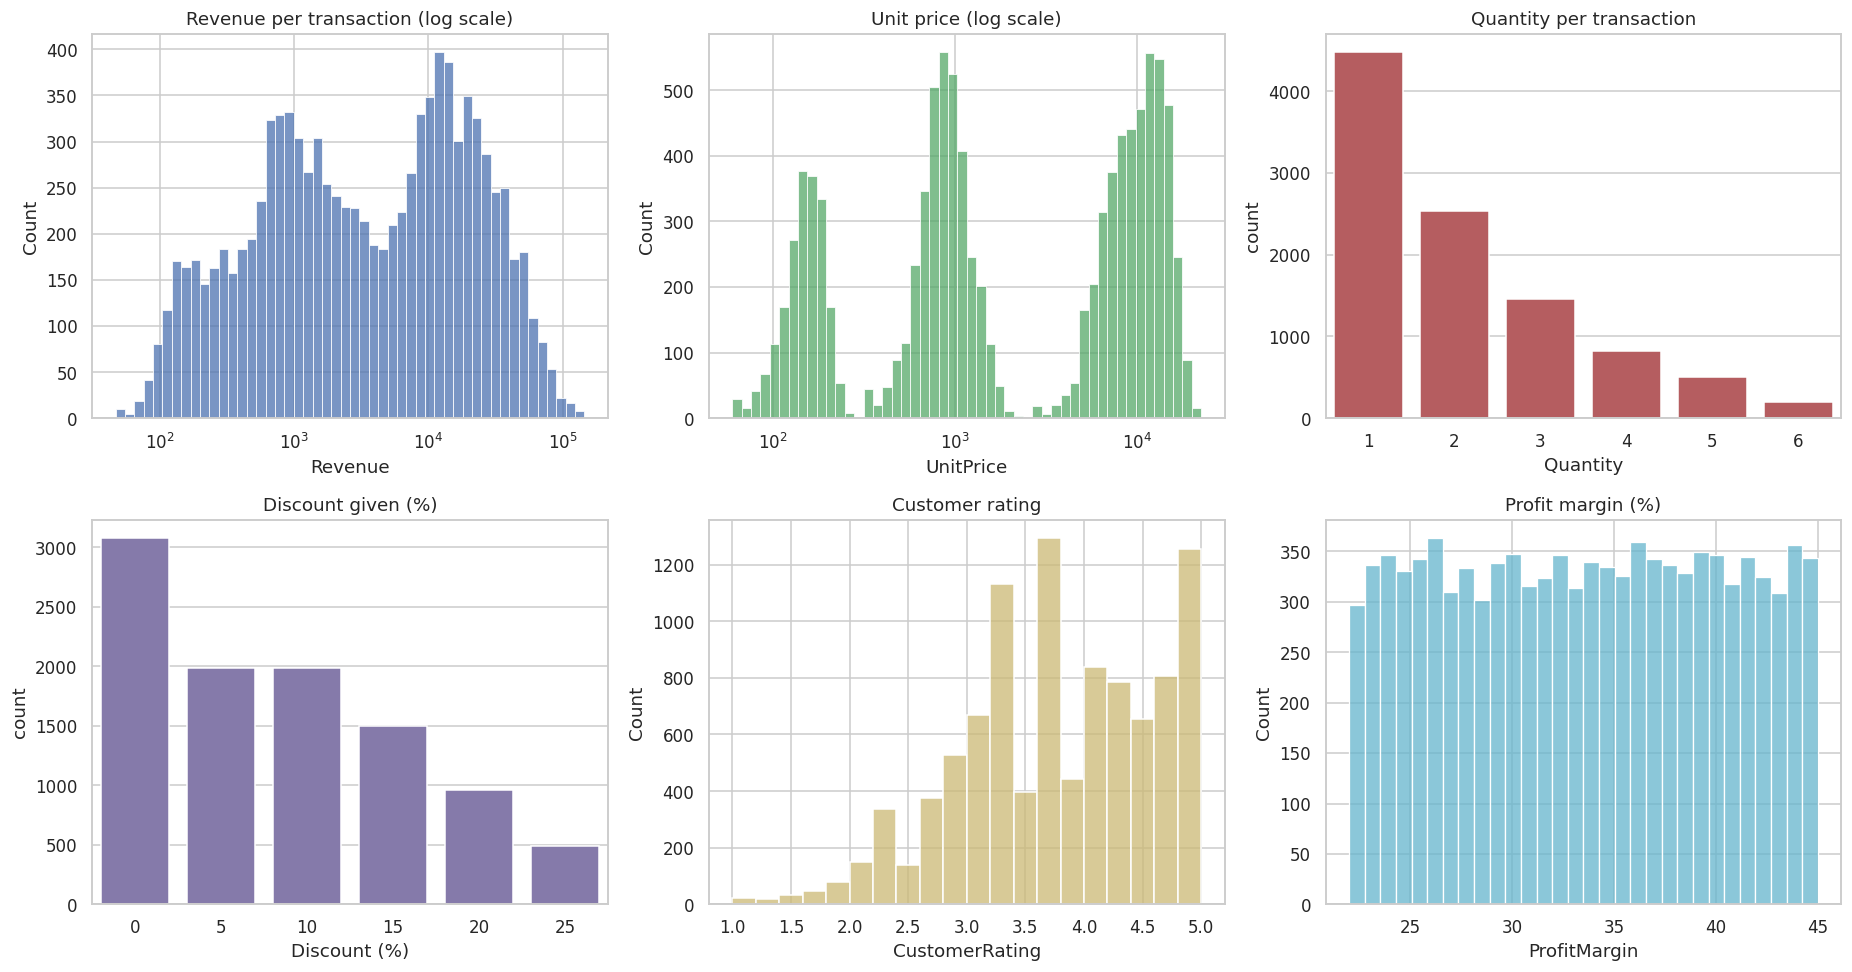

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

sns.histplot(df["Revenue"], bins=50, log_scale=True, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Revenue per transaction (log scale)")

sns.histplot(df["UnitPrice"], bins=50, log_scale=True, ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("Unit price (log scale)")

sns.countplot(x="Quantity", data=df, ax=axes[0, 2], color="#C44E52")
axes[0, 2].set_title("Quantity per transaction")

sns.countplot(x=(df["Discount"] * 100).astype(int), data=df, ax=axes[1, 0], color="#8172B2")
axes[1, 0].set_title("Discount given (%)")
axes[1, 0].set_xlabel("Discount (%)")

sns.histplot(df["CustomerRating"], binwidth=0.2, binrange=(1, 5), ax=axes[1, 1], color="#CCB974")
axes[1, 1].set_title("Customer rating")

sns.histplot(df["ProfitMargin"], bins=30, ax=axes[1, 2], color="#64B5CD")
axes[1, 2].set_title("Profit margin (%)")

save_fig("01_distributions")

- **Revenue and unit price** are skewed to the right. On a log scale unit price splits into three clear price tiers (roughly ₹150, ₹900 and ₹10,000), which is why revenue shows two broad humps.
- **Quantity** drops off quickly: most transactions are for 1 or 2 items.
- **Discount** is concentrated at the low end, with 0% the most common value.
- **Rating** bunches between 3 and 5 and has a long tail towards the low end.
- **Profit margin** is almost flat between 22% and 45%. Real margins rarely look this even, which I come back to in the limitations.

### 4.3 Category performance

In [22]:
category_summary = (
    df.groupby("Category", observed=True)
      .agg(Orders=("TransactionID", "count"),
           Revenue=("Revenue", "sum"),
           Profit=("Profit", "sum"),
           AvgMargin=("ProfitMargin", "mean"),
           AvgOrderValue=("Revenue", "mean"))
      .sort_values("Revenue", ascending=False)
)
category_summary["RevenueShare%"] = category_summary["Revenue"] / category_summary["Revenue"].sum() * 100
category_summary

,Orders,Revenue,Profit,AvgMargin,AvgOrderValue,RevenueShare%
Category,,,,,,
Electronics,2972,"78,710,440.08","26,260,211.35",33.43,"26,484.00",71.22
Furniture,1495,"23,957,101.19","8,125,095.69",33.82,"16,024.82",21.68
Clothing,2534,"4,537,683.14","1,528,201.21",33.60,"1,790.72",4.11
Sports,979,"2,638,533.99","885,500.86",33.61,"2,695.13",2.39
Groceries,2020,"668,018.92","224,215.99",33.45,330.70,0.60


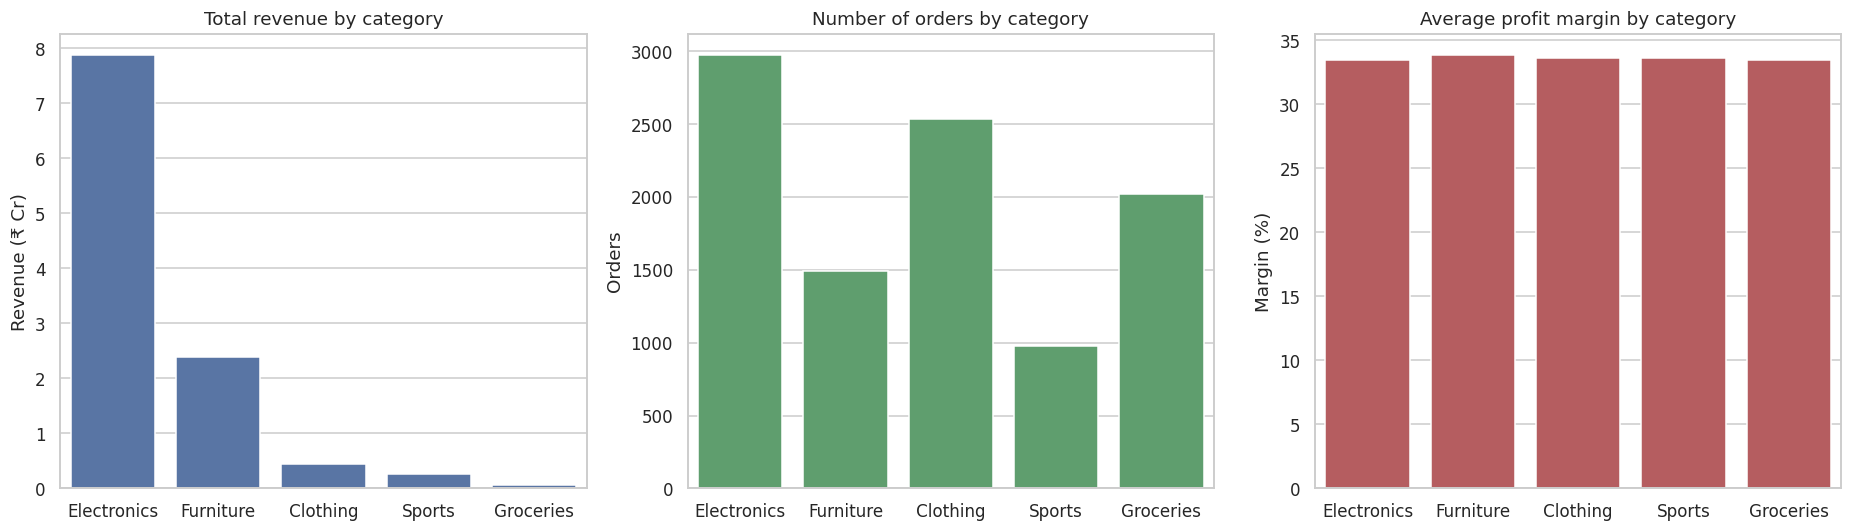

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(x=category_summary.index.astype(str), y=category_summary["Revenue"] / 1e7, ax=axes[0], color="#4C72B0")
axes[0].set_title("Total revenue by category")
axes[0].set_ylabel("Revenue (₹ Cr)")
axes[0].set_xlabel("")

sns.barplot(x=category_summary.index.astype(str), y=category_summary["Orders"], ax=axes[1], color="#55A868")
axes[1].set_title("Number of orders by category")
axes[1].set_ylabel("Orders")
axes[1].set_xlabel("")

sns.barplot(x=category_summary.index.astype(str), y=category_summary["AvgMargin"], ax=axes[2], color="#C44E52")
axes[2].set_title("Average profit margin by category")
axes[2].set_ylabel("Margin (%)")
axes[2].set_xlabel("")

save_fig("02_category_performance")

### 4.4 Region, channel, payment method, gender, city and product

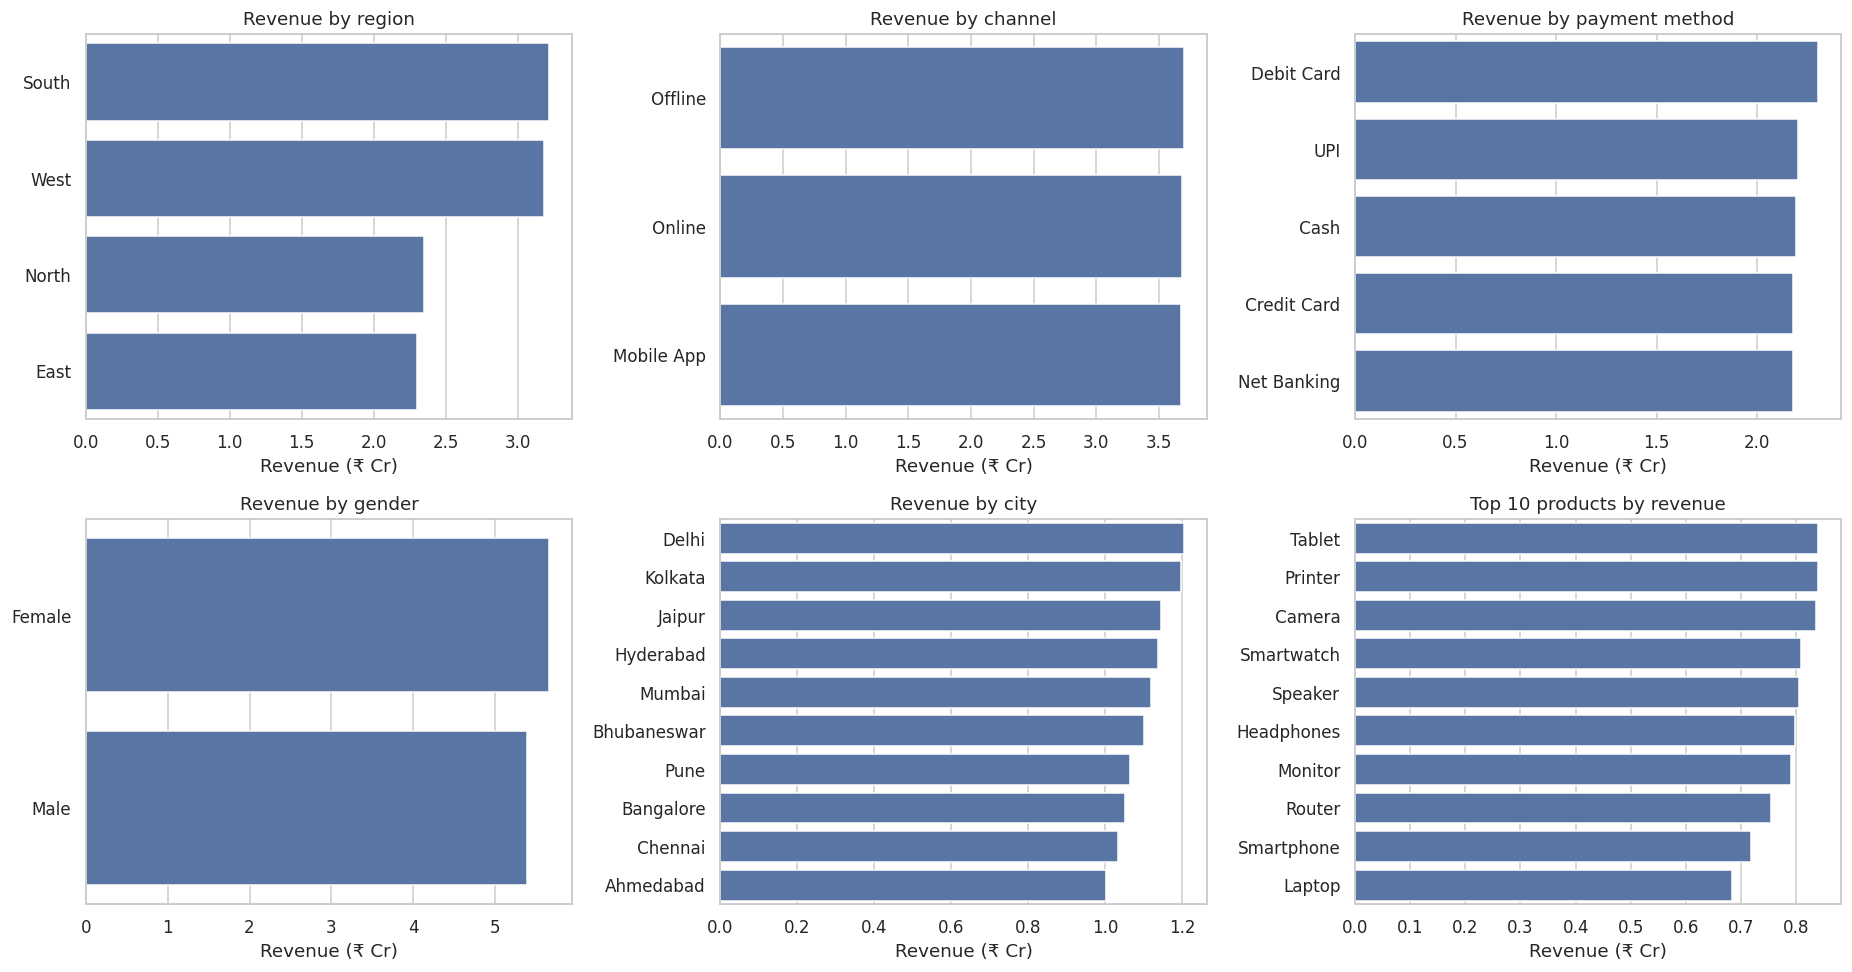

In [24]:
segments = {
    "Region": "Region",
    "Channel": "Channel",
    "Payment method": "PaymentMethod",
    "Gender": "Gender",
    "City": "City",
    "Top 10 products": "ProductName",
}

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (title, col) in zip(axes.flat, segments.items()):
    totals = df.groupby(col, observed=True)["Revenue"].sum().sort_values(ascending=False) / 1e7
    if title.startswith("Top"):
        totals = totals.head(10)
    sns.barplot(x=totals.values, y=totals.index.astype(str), orient="h", ax=ax, color="#4C72B0")
    ax.set_title(f"Revenue by {title.lower()}" if not title.startswith("Top") else "Top 10 products by revenue")
    ax.set_xlabel("Revenue (₹ Cr)")
    ax.set_ylabel("")

save_fig("03_segments")

In [25]:
# The same breakdown as numbers: each segment's share of total revenue
for title, col in list(segments.items())[:5]:
    share = (df.groupby(col, observed=True)["Revenue"].sum() / df["Revenue"].sum() * 100).sort_values(ascending=False)
    print(f"{title}:")
    print(share.round(1).to_string(), "\n")

Region:
Region
South   29.10
West    28.80
North   21.30
East    20.80 

Channel:
Channel
Offline      33.40
Online       33.30
Mobile App   33.20 

Payment method:
PaymentMethod
Debit Card    20.80
UPI           19.90
Cash          19.80
Credit Card   19.70
Net Banking   19.70 

Gender:
Gender
Female   51.20
Male     48.80 

City:
City
Delhi         10.90
Kolkata       10.80
Jaipur        10.40
Hyderabad     10.30
Mumbai        10.10
Bhubaneswar   10.00
Pune           9.60
Bangalore      9.50
Chennai        9.30
Ahmedabad      9.10 



### 4.5 Trends over time

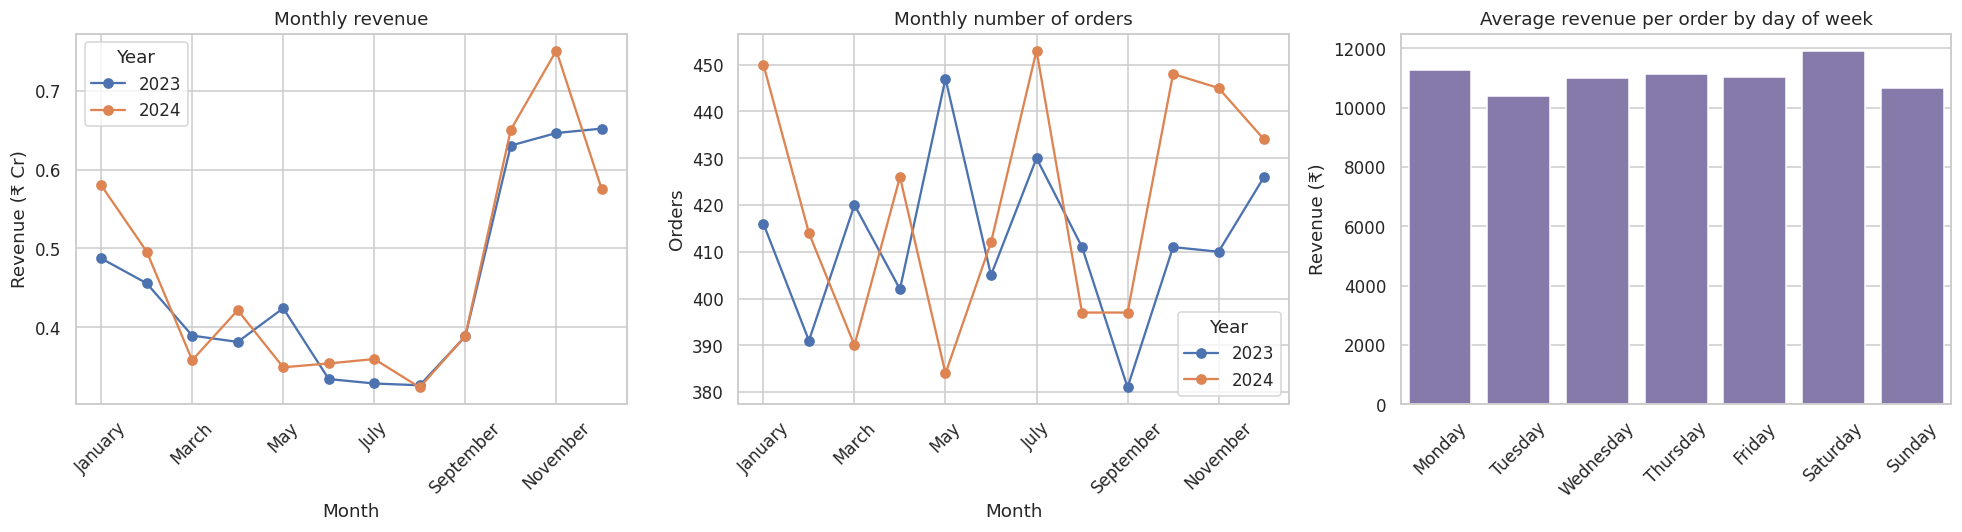

In [26]:
monthly_revenue = df.pivot_table(index="Month", columns="Year", values="Revenue", aggfunc="sum", observed=True) / 1e7
monthly_orders  = df.pivot_table(index="Month", columns="Year", values="TransactionID", aggfunc="count", observed=True)
dow_avg         = df.groupby("DayOfWeek", observed=True)["Revenue"].mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

monthly_revenue.plot(marker="o", ax=axes[0])
axes[0].set_title("Monthly revenue")
axes[0].set_ylabel("Revenue (₹ Cr)")
axes[0].tick_params(axis="x", rotation=45)

monthly_orders.plot(marker="o", ax=axes[1])
axes[1].set_title("Monthly number of orders")
axes[1].set_ylabel("Orders")
axes[1].tick_params(axis="x", rotation=45)

sns.barplot(x=dow_avg.index.astype(str), y=dow_avg.values, ax=axes[2], color="#8172B2")
axes[2].set_title("Average revenue per order by day of week")
axes[2].set_ylabel("Revenue (₹)")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=45)

save_fig("04_trends")

In [27]:
yearly = df.groupby("Year")["Revenue"].sum()
print("Revenue by year:")
for year, value in yearly.items():
    print(f"  {year}: {fmt_inr(value)}")
print(f"Year-on-year growth: {(yearly[2024] / yearly[2023] - 1) * 100:.1f}%\n")

print("Revenue by quarter (₹ Cr):")
print((df.pivot_table(index="Quarter", columns="Year", values="Revenue", aggfunc="sum", observed=True) / 1e7).round(2))

Revenue by year:
  2023: ₹5.44 Cr
  2024: ₹5.61 Cr
Year-on-year growth: 3.0%

Revenue by quarter (₹ Cr):
Year     2023  2024
Quarter            
Q1       1.33  1.43
Q2       1.14  1.12
Q3       1.04  1.07
Q4       1.93  1.98


In [28]:
# A while loop: how many days did it take to cross the first ₹1 crore?
daily = df.groupby("Date")["Revenue"].sum().sort_index()

target = 1e7
running_total, day_index = 0, 0
while running_total < target:
    running_total += daily.iloc[day_index]
    day_index += 1

print(f"Cumulative revenue crossed {fmt_inr(target)} after {day_index} days, on {daily.index[day_index - 1].date()}.")

Cumulative revenue crossed ₹1.00 Cr after 64 days, on 2023-03-05.


### 4.6 Relationships between features

Start with the correlation matrix, then look at specific pairs.

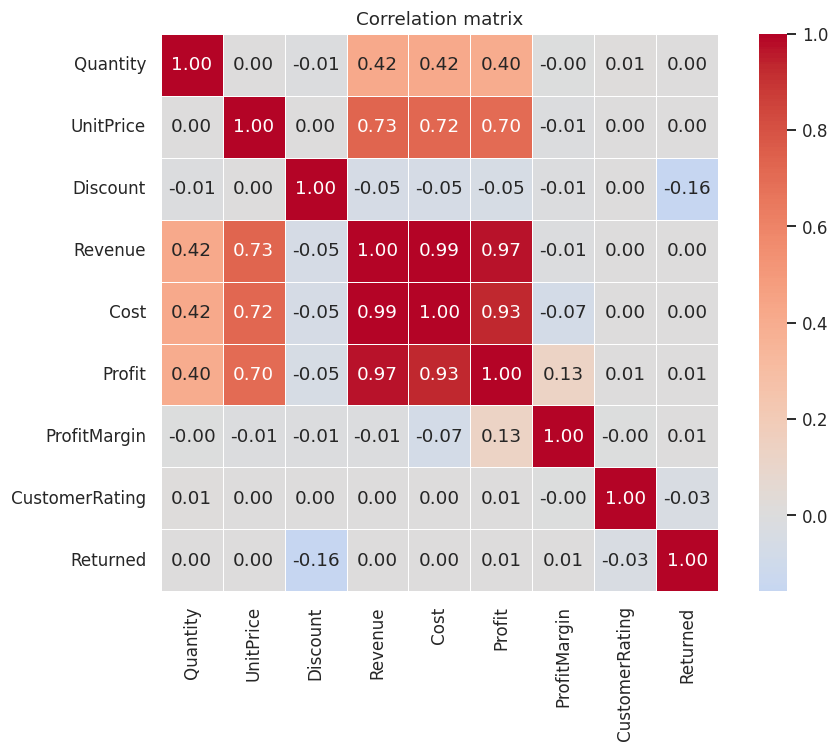

In [29]:
corr_cols = ["Quantity", "UnitPrice", "Discount", "Revenue", "Cost", "Profit", "ProfitMargin", "CustomerRating", "Returned"]
corr = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, square=True)
plt.title("Correlation matrix")
save_fig("05_correlation_heatmap")

In [30]:
# Strongest pairs, ignoring the trivial ones (Revenue vs Cost vs Profit are built from each other)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("correlation")
pairs = pairs[pairs.abs().sort_values(ascending=False).index]
pairs.head(8).round(2)

Revenue    Cost      0.99
           Profit    0.97
Cost       Profit    0.93
UnitPrice  Revenue   0.73
           Cost      0.72
           Profit    0.70
Quantity   Revenue   0.42
           Cost      0.42
Name: correlation, dtype: float64

### Relationship dashboard
Six panels showing how the main features relate to each other. This is the visual summary the Week 4 brief asks for.

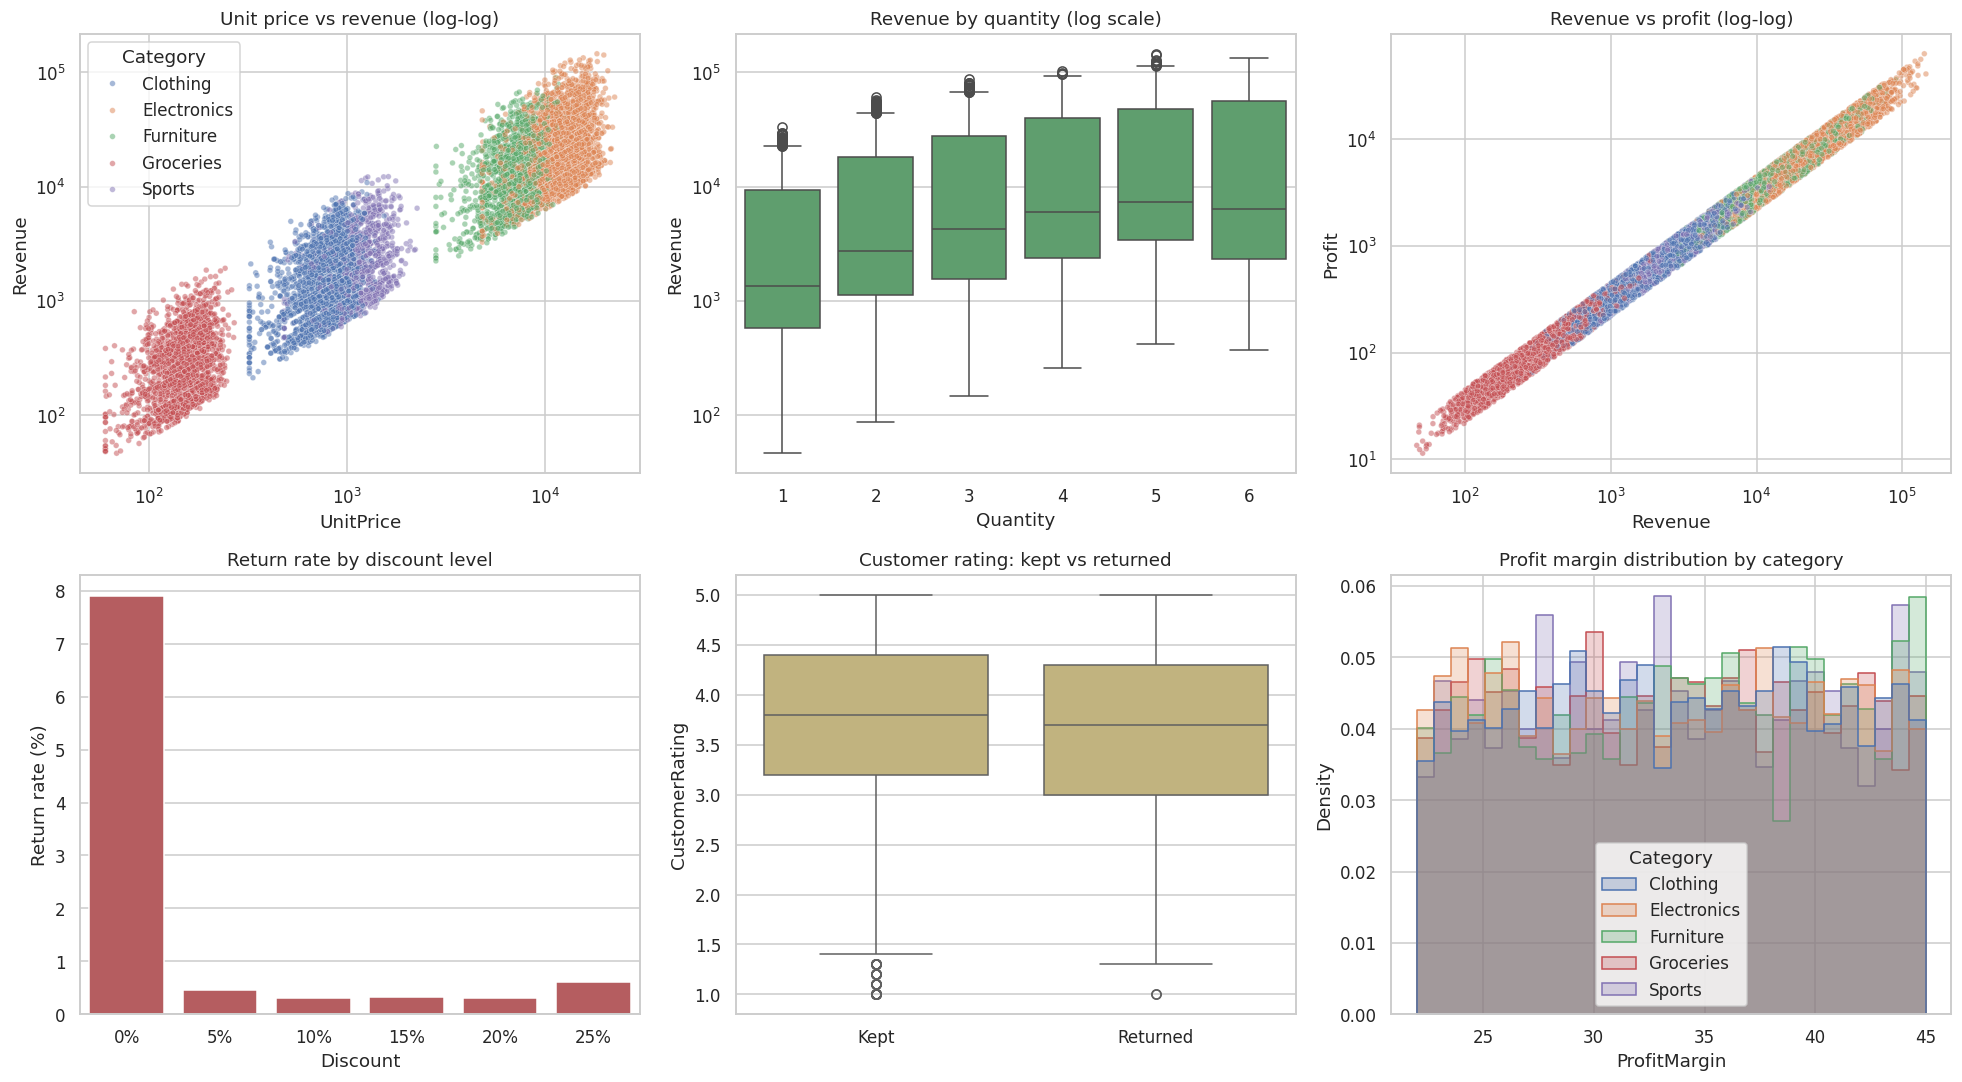

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.scatterplot(data=df, x="UnitPrice", y="Revenue", hue="Category", alpha=0.5, s=14, ax=axes[0, 0])
axes[0, 0].set(xscale="log", yscale="log", title="Unit price vs revenue (log-log)")

sns.boxplot(data=df, x="Quantity", y="Revenue", ax=axes[0, 1], color="#55A868")
axes[0, 1].set(yscale="log", title="Revenue by quantity (log scale)")

sns.scatterplot(data=df, x="Revenue", y="Profit", hue="Category", alpha=0.5, s=14, ax=axes[0, 2], legend=False)
axes[0, 2].set(xscale="log", yscale="log", title="Revenue vs profit (log-log)")

return_rate = df.groupby("Discount")["Returned"].mean() * 100
sns.barplot(x=[f"{d:.0%}" for d in return_rate.index], y=return_rate.values, ax=axes[1, 0], color="#C44E52")
axes[1, 0].set(title="Return rate by discount level", xlabel="Discount", ylabel="Return rate (%)")

sns.boxplot(data=df, x="ReturnStatus", y="CustomerRating", ax=axes[1, 1], color="#CCB974")
axes[1, 1].set(title="Customer rating: kept vs returned", xlabel="")

sns.histplot(data=df, x="ProfitMargin", hue="Category", element="step", stat="density",
             common_norm=False, bins=30, ax=axes[1, 2])
axes[1, 2].set(title="Profit margin distribution by category")

save_fig("06_relationship_dashboard")

In [32]:
print("Return rate by discount band:")
print((df.groupby("DiscountBand")["Returned"].agg(orders="count", returns="sum", rate="mean")
         .assign(rate=lambda t: t["rate"] * 100)).round(2))

print("\nAverage rating, kept vs returned:")
print(df.groupby("ReturnStatus")["CustomerRating"].mean().round(2))

Return rate by discount band:
               orders  returns  rate
DiscountBand                        
High (15-25%)    2957       11  0.37
Low (5-10%)      3968       15  0.38
No discount      3075      243  7.90

Average rating, kept vs returned:
ReturnStatus
Kept       3.77
Returned   3.59
Name: CustomerRating, dtype: float64


A pairplot gives one more look at all the numeric relationships at once. I use a random sample of 800 rows and the log versions of the skewed columns so it stays readable.

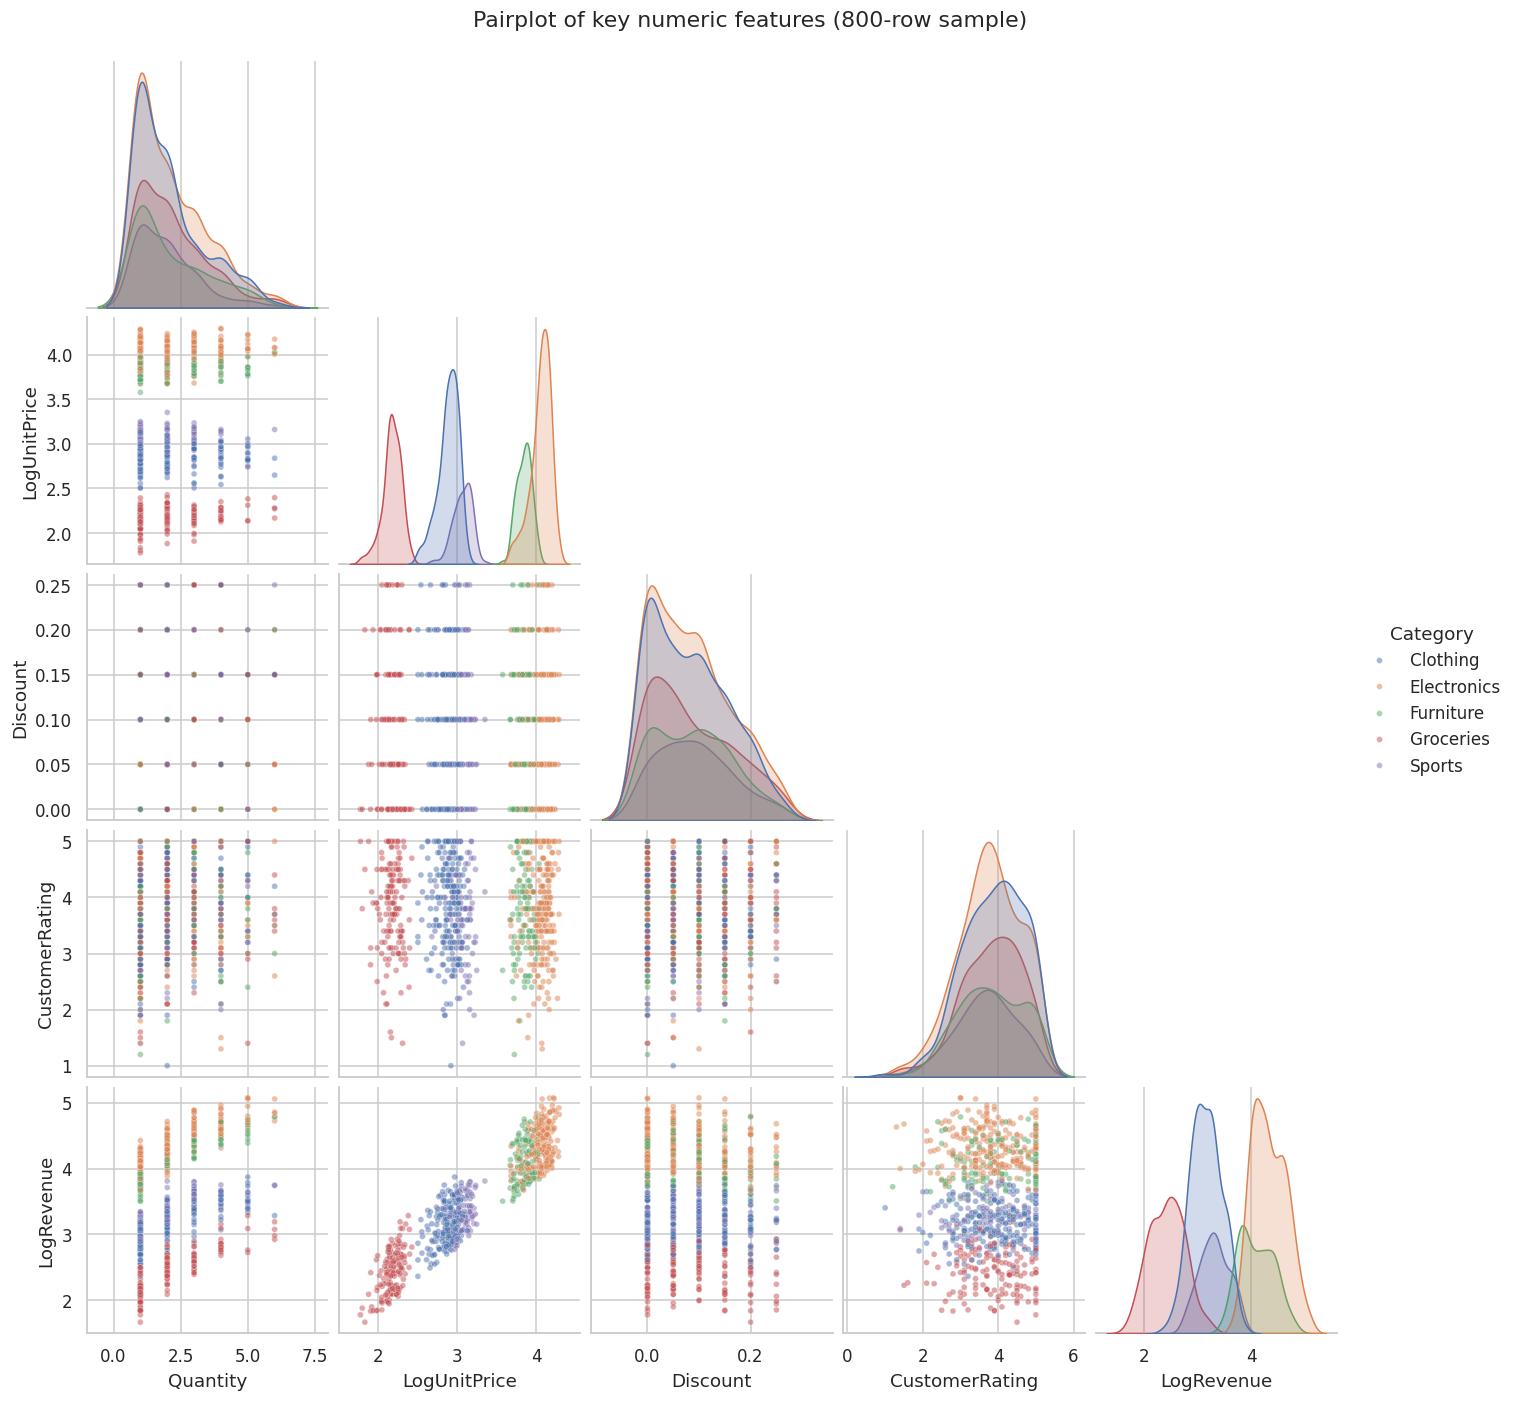

In [33]:
sample = df.sample(800, random_state=42)
g = sns.pairplot(sample[["Quantity", "LogUnitPrice", "Discount", "CustomerRating", "LogRevenue", "Category"]],
                 hue="Category", corner=True, plot_kws={"alpha": 0.5, "s": 15})
g.figure.suptitle("Pairplot of key numeric features (800-row sample)", y=1.02)
g.savefig("images/07_pairplot.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Key findings

### What the data says

1. **Electronics carries the business.** It is 29.7% of orders but 71.2% of revenue, and Electronics plus Furniture together make up about 93%. Groceries is 20.2% of orders and just 0.6% of revenue, so lots of transactions do not mean much money here.
2. **Margins are the same everywhere.** Average margin sits between 33.4% and 33.8% in every category, and the overall margin is 33.5%. Categories differ in how much they sell and how big each order is, not in how profitable each sale is.
3. **Q4 is the peak, but not because of more orders.** October to December brings in 35.3% of all revenue, yet monthly order counts stay in a narrow band (about 780 to 880). The lift comes from the month-level multiplier found in section 3.6.
4. **Channels, payment methods, gender and cities are almost evenly split.** Offline, Online and Mobile App each hold about a third of revenue, the five payment methods are within 1.1 points of each other, and cities range from 9.1% to 10.9%. South and West look bigger (29.1% and 28.8%) only because they have three cities each while North and East have two.
5. **Growth was modest.** Revenue went from ₹5.44 Cr in 2023 to ₹5.61 Cr in 2024, up 3.0%.
6. **Returns are rare but oddly tied to discounts.** The overall return rate is 2.69%. Orders with no discount were returned 7.9% of the time, against about 0.4% for discounted orders, so 243 of the 269 returns came from undiscounted sales. Returned orders also carry a lower average rating (3.59 against 3.77). Furniture has the highest return rate (3.6%).
7. **What moves revenue.** Revenue correlates strongly with unit price (0.73) and moderately with quantity (0.42). Customer rating is close to uncorrelated with everything else, including price and profit.

### Limits of this analysis

- **The data looks generated, not collected.** Margins are almost uniformly spread between 22% and 45%, each month has one exact revenue multiplier, and most splits are near-perfectly even. That is useful for practising the workflow, but I would not draw real business conclusions from it.
- **EDA shows association, not cause.** The link between discounts and returns is a pattern worth testing properly, not proof that discounts reduce returns.
- **Some things are assumptions.** The currency is assumed to be INR, and the month multiplier is inferred from the numbers because the file does not document how Revenue was built.
- **There is no customer ID.** That rules out repeat-purchase or customer-level analysis with this file.
- **Next steps** for a later module: a statistical test on the discount and return link, a time-series view of seasonality, and a simple regression to predict profit or returns.